[Project Details](https://docs.google.com/document/d/1yJbsty_9ebmV0zXpsrc02Q1w8UoZQ_A_qL6Zv7haIPc/edit?usp=sharing)

# Fine Tune YOLO model to identify Sports Balls

In [ ]:
!pip install ultralytics

In [ ]:
"""
Fine-tune a YOLO model to detect sports balls:
basketball, volleyball, soccer, tennis, and baseball.

The Roboflow dataset has 39 messy classes (duplicates, other languages, other objects).
This script first builds a clean copy of the dataset that keeps only our 5 classes,
then trains on it.

Setup:
    pip install ultralytics

Usage:
    python train_sports_balls.py
"""

import shutil
from collections import Counter
from pathlib import Path

import yaml
from ultralytics import YOLO

# ----------------------------- Configuration -----------------------------

SOURCE_DIR = Path("sports-ball-1")   # Folder Roboflow downloaded (contains data.yaml, train/, valid/, test/)
OUTPUT_DIR = Path("balls_clean")     # Where the cleaned dataset will be written

BASE_MODEL = "yolo11n.pt"            # Try yolo11s.pt / yolo11m.pt for more accuracy
EPOCHS = 50
IMAGE_SIZE = 640
BATCH_SIZE = 16                      # Lower this if you run out of GPU memory
DEVICE = 0                           # 0 = first GPU, "cpu" = CPU, "mps" = Apple Silicon
RUN_NAME = "sports_balls"

# Our final classes. The position in this list becomes the class ID (0-3).
CLASS_NAMES = ["basketball", "volleyball", "soccer", "tennis"]

# Which original Roboflow class names map to each of our classes.
# Any original class not listed here is dropped.
CLASS_MAP = {
    "basketball": ["Basketball", "basketball", "basketbol topu"],
    "volleyball": ["Volleyball", "volleyball", "voleybol topu"],
    "soccer": ["Soccer", "Soccer ball", "soccer", "futbol topu"],
    "tennis": ["Tennis Ball", "Tennis-Ball", "Tennis-ball", "TennisBall", "tennis", "tennis-ball"],
}

SPLITS = ["train", "valid", "test"]

# ------------------------------ Dataset prep ------------------------------


def build_id_map(source_yaml: Path) -> dict[int, int]:
    """Map each old class ID in the Roboflow dataset to its new ID (0-3)."""
    with open(source_yaml) as f:
        original_names = yaml.safe_load(f)["names"]
    if isinstance(original_names, dict):
        original_names = [original_names[i] for i in sorted(original_names)]

    name_to_new_id = {
        name: CLASS_NAMES.index(target)
        for target, names in CLASS_MAP.items()
        for name in names
    }
    return {
        old_id: name_to_new_id[name]
        for old_id, name in enumerate(original_names)
        if name in name_to_new_id
    }


def remap_split(split: str, id_map: dict[int, int], counts: Counter) -> None:
    """Copy one split (train/valid/test), keeping only our classes with new IDs."""
    images_in = SOURCE_DIR / split / "images"
    labels_in = SOURCE_DIR / split / "labels"
    if not images_in.exists():
        return

    images_out = OUTPUT_DIR / split / "images"
    labels_out = OUTPUT_DIR / split / "labels"
    images_out.mkdir(parents=True, exist_ok=True)
    labels_out.mkdir(parents=True, exist_ok=True)

    for label_file in labels_in.glob("*.txt"):
        new_lines = []
        for line in label_file.read_text().splitlines():
            parts = line.split()
            if parts and int(parts[0]) in id_map:
                new_id = id_map[int(parts[0])]
                new_lines.append(" ".join([str(new_id)] + parts[1:]))
                counts[new_id] += 1

        if not new_lines:
            continue  # Skip images that contain none of our classes

        image = next(images_in.glob(f"{label_file.stem}.*"), None)
        if image is None:
            continue
        shutil.copy(image, images_out / image.name)
        (labels_out / label_file.name).write_text("\n".join(new_lines) + "\n")


def write_data_yaml() -> Path:
    """Create the data.yaml that tells YOLO where the cleaned data is and what the classes are."""
    config = {
        "path": str(OUTPUT_DIR.resolve()),
        "train": "train/images",
        "val": "valid/images",
        "names": {i: name for i, name in enumerate(CLASS_NAMES)},
    }
    if (OUTPUT_DIR / "test" / "images").exists():
        config["test"] = "test/images"

    yaml_path = OUTPUT_DIR / "data.yaml"
    with open(yaml_path, "w") as f:
        yaml.safe_dump(config, f, sort_keys=False)
    print(f"Wrote dataset config to {yaml_path}")
    return yaml_path


def prepare_dataset() -> Path:
    """Build the cleaned dataset and return the path to its data.yaml."""
    if not (SOURCE_DIR / "data.yaml").exists():
        raise FileNotFoundError(f"Couldn't find {SOURCE_DIR}/data.yaml. Check SOURCE_DIR.")

    id_map = build_id_map(SOURCE_DIR / "data.yaml")
    counts: Counter = Counter()
    for split in SPLITS:
        remap_split(split, id_map, counts)

    print("\nBox counts per class:")
    for i, name in enumerate(CLASS_NAMES):
        note = "  <-- no examples, model can't learn this class" if counts[i] == 0 else ""
        print(f"  {name:<12} {counts[i]}{note}")
    print()

    return write_data_yaml()


# --------------------------------- Training ---------------------------------


def train(data_yaml: Path) -> YOLO:
    """Fine-tune the pretrained model on our dataset."""
    model = YOLO(BASE_MODEL)  # Loads pretrained weights (transfer learning)
    model.train(
        data=str(data_yaml),
        epochs=EPOCHS,
        imgsz=IMAGE_SIZE,
        batch=BATCH_SIZE,
        device=DEVICE,
        name=RUN_NAME,
        patience=10,       # Stop early if validation doesn't improve for 10 epochs
        hsv_h=0.015,
        hsv_s=0.7,
        hsv_v=0.4,
        fliplr=0.5,
        mosaic=1.0,
    )
    return model


def validate(model: YOLO) -> None:
    """Evaluate on the validation set and print key metrics."""
    metrics = model.val()
    print(f"\nmAP@50:     {metrics.box.map50:.3f}")
    print(f"mAP@50-95:  {metrics.box.map:.3f}")


def predict(weights_path: Path, source: str) -> None:
    """Run the trained model on an image, folder, or video and save annotated results."""
    model = YOLO(str(weights_path))
    model.predict(source=source, conf=0.25, save=True, name=f"{RUN_NAME}_predictions")


def main() -> None:
    data_yaml = prepare_dataset()
    model = train(data_yaml)
    validate(model)

    best_weights = Path(model.trainer.save_dir) / "weights" / "best.pt"
    print(f"\nTraining complete. Best weights saved to: {best_weights}")

    # Uncomment to try the model on your own images or videos:
    # predict(best_weights, source="path/to/test_image.jpg")


if __name__ == "__main__":
    main()


Box counts per class:
  basketball   1251
  volleyball   146
  soccer       2023
  tennis       1403

Wrote dataset config to balls_clean/data.yaml
Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=balls_clean/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.

# Get Edge SAM model

In [ ]:
!git clone https://github.com/chongzhou96/EdgeSAM.git
%cd EdgeSAM
# Remove strict torch version matching from requirements to use Colab's pre-installed optimized torch
!pip install -q -r requirements.txt
!pip install -q -e .

!mkdir -p weights
!wget -q -P weights/ https://huggingface.co/spaces/chongzhou/EdgeSAM/resolve/main/weights/edge_sam_3x.pth

!pip install -q mmengine
!pip install loralib
!pip install -q yacs timm
%cd ..

fatal: destination path 'EdgeSAM' already exists and is not an empty directory.
/content/EdgeSAM
ERROR: Could not find a version that satisfies the requirement torch==2.0.0 (from versions: 2.5.0, 2.5.1, 2.6.0, 2.7.0, 2.7.1, 2.8.0, 2.9.0, 2.9.1, 2.10.0, 2.11.0, 2.12.0, 2.12.1, 2.13.0, 2.14.0, 2.14.1, 2.15.0)
ERROR: No matching distribution found for torch==2.0.0
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for edge_sam (pyproject.toml) ... done


In [ ]:
sam_file = "/content/EdgeSAM/edge_sam/modeling/sam.py"

with open(sam_file, "r") as f:
    code = f.read()

old_imports = """from mmdet.models.dense_heads import RPNHead, CenterNetUpdateHead
from mmdet.models.necks import FPN
from projects.EfficientDet import efficientdet"""

new_imports = """try:
    from mmdet.models.dense_heads import RPNHead, CenterNetUpdateHead
    from mmdet.models.necks import FPN
    from projects.EfficientDet import efficientdet
except ImportError:
    pass"""

if old_imports in code:
    with open(sam_file, "w") as f:
        f.write(code.replace(old_imports, new_imports))
    print("Patched sam.py successfully!")
else:
    print("Already patched or lines not found.")

Already patched or lines not found.


#Identify Ball Location, Crop, and Segment

In [ ]:
def detect_balls(model, frame, conf_threshold):
  """Return every detection above the confidence threshold.

  Each detection is a dict with its box (x1, y1, x2, y2), confidence, and class label.
  """
  result = model.predict(source=frame, conf=conf_threshold, verbose=False)[0]

  detections = []
  for box in result.boxes:
      x1, y1, x2, y2 = (int(value) for value in box.xyxy[0].tolist())
      detections.append({"box": (x1, y1, x2, y2), "conf": float(box.conf), "label": model.names[int(box.cls)]})
  return detections

def BestDetection(detections):
  if len(detections) == 0:
      return None
  best = max(detections, key=lambda d: d["conf"])
  return best["box"]

# RANSAC the contour

In [ ]:
import numpy as np

def ransac(pixels_vu: np.ndarray, alpha, beta, u_0, v_0,
           pixel_thresh=3.0, num_iters: int = 300, seed: int = 0):
  """
  Fit a 3D cone to contour pixels with RANSAC.
  pixels_vu: (N, 2) array of [v, u] = [row, col] in FULL-FRAME pixel coordinates.
  Returns: (inlier_rays, inlier_mask) or (None, None) if fitting fails.
  """
  if len(pixels_vu) < 6:
    return None, None

  rng = np.random.default_rng(seed)

  rays = np.column_stack([(pixels_vu[:, 1] - u_0) / alpha,
                          (pixels_vu[:, 0] - v_0) / beta,
                          np.ones(len(pixels_vu))])
  norm_rays = rays / np.linalg.norm(rays, axis=1, keepdims=True)  # (N, 3)

  angle_thresh = 2 * pixel_thresh / (alpha + beta)  # angular size of `pixel_thresh` pixels (radians)

  N = len(norm_rays)
  ones_3 = np.ones(3)
  best_inliers = None
  best_count = 0

  for _ in range(num_iters):
    idx = rng.choice(N, 3, replace=False)
    try:
      x = np.linalg.solve(norm_rays[idx], ones_3)
    except np.linalg.LinAlgError:
      continue  # collinear rays

    norm_x = np.linalg.norm(x)  # = 1 / cos(cone half-angle)
    if norm_x <= 1.0:
      continue

    center_ray = x / norm_x
    cone_angle = np.arccos(1.0 / norm_x)

    ray_angles = np.arccos(np.clip(norm_rays @ center_ray, -1.0, 1.0))
    inliers = np.abs(ray_angles - cone_angle) < angle_thresh
    count = int(np.sum(inliers))

    if count > best_count:
      best_count = count
      best_inliers = inliers

  if best_inliers is None or best_count < 6:
    return None, None

  return norm_rays[best_inliers], best_inliers

def project_cone_silhouette(axis, half_angle, alpha, beta, u_0, v_0, num_points=200):
  """
  Project the fitted cone back into the image.
  Returns an (M, 2) array of [x, y] = [u, v] pixel coordinates tracing the ball's outline.
  """
  # two unit vectors perpendicular to the axis
  helper = np.array([1.0, 0.0, 0.0]) if abs(axis[0]) < 0.9 else np.array([0.0, 1.0, 0.0])
  e1 = np.cross(axis, helper)
  e1 /= np.linalg.norm(e1)
  e2 = np.cross(axis, e1)

  # rays that lie exactly on the cone surface
  phi = np.linspace(0, 2 * np.pi, num_points, endpoint=False)
  rays = np.cos(half_angle) * axis + np.sin(half_angle) * (np.outer(np.cos(phi), e1) +
                                                           np.outer(np.sin(phi), e2))

  rays = rays[rays[:, 2] > 1e-6]  # keep only rays pointing in front of the camera
  u = alpha * rays[:, 0] / rays[:, 2] + u_0
  v = beta * rays[:, 1] / rays[:, 2] + v_0
  return np.column_stack([u, v])

def draw_fitted_ball(image, axis, half_angle, alpha, beta, u_0, v_0, color, thickness=2):
  """Draw the full, closed, fitted outline of the ball on `image`."""
  outline = project_cone_silhouette(axis, half_angle, alpha, beta, u_0, v_0)
  points = np.round(outline).astype(np.int32).reshape(-1, 1, 2)
  cv2.polylines(image, [points], True, color, thickness)

#My Portion: Inverse Camera to Ball Position Algorithm

In [ ]:
settings = "4K"
if settings == "1080p iphone":
  # initialize parameter values of a 1080p iphone video
  width = 1920
  height = 1080
  focalLength = 0.00676  # 6.76 mm physical focal length (24 mm equivalent)
  p_x = 0.0000048        # 4.8 µm effective pixel pitch at 1080p
  p_y = 0.0000048
  alpha = focalLength / p_x  # ~1408 px
  beta = focalLength / p_y   # ~1408 px
  u_0 = width // 2           # 960
  v_0 = height // 2          # 540
  R_ball = 0.119 # 0.119 m for standard NBA men's size 7 ball
elif settings == "4K":
  # initialize parameter values of a 4K video
  width = 3840
  height = 2160
  focalLength = 0.00676  # 6.76 mm physical focal length (24 mm equivalent)
  p_x = 0.0000024       # 2.4 µm effective pixel pitch at 1080p
  p_y = 0.0000024
  alpha = focalLength / p_x  # ~2817 px
  beta = focalLength / p_y   # ~2817 px
  u_0 = width // 2           # 1920
  v_0 = height // 2          # 1080
  R_ball = 0.119 # 0.119 m for standard NBA men's size 7 ball

In [ ]:
import numpy as np

def randomProjectedSphere(width, height, alpha, beta, u_0, v_0, R_ball, dropRate, min_pixels=10):
    rng = np.random.default_rng()

    # Exact camera frustum limits in normalized coordinates
    max_x_ratio = u_0 / alpha
    max_y_ratio = v_0 / beta

    while True:
        # 1. Pick a random true 3D ball center guaranteed to be inside the camera FOV
        z_c = rng.uniform(25, 30)
        x_c = rng.uniform(-max_x_ratio * z_c, max_x_ratio * z_c)
        y_c = rng.uniform(-max_y_ratio * z_c, max_y_ratio * z_c)
        p_c = np.array([x_c, y_c, z_c])

        # 2. Compute the 3D tangent circle (silhouette) on the sphere
        d = np.linalg.norm(p_c)
        c_hat = p_c / d
        cos_theta = np.sqrt(1 - (R_ball / d)**2)

        ring_center = (d * cos_theta**2) * c_hat
        ring_radius = R_ball * cos_theta

        # Build two orthonormal basis vectors (e1, e2) perpendicular to c_hat
        ref = np.array([1.0, 0.0, 0.0]) if abs(c_hat[0]) < 0.9 else np.array([0.0, 1.0, 0.0])
        e1 = np.cross(c_hat, ref)
        e1 /= np.linalg.norm(e1)
        e2 = np.cross(c_hat, e1)

        # 3. Sample 3D points on the silhouette and project to 2D pixels
        angles = rng.uniform(0, 2 * np.pi, size=int(150 * (1 - dropRate)))
        pts_3d = ring_center + ring_radius * (np.outer(np.cos(angles), e1) + np.outer(np.sin(angles), e2))

        u = np.round(alpha * (pts_3d[:, 0] / pts_3d[:, 2]) + u_0).astype(int)
        v = np.round(beta * (pts_3d[:, 1] / pts_3d[:, 2]) + v_0).astype(int)

        valid = (u >= 0) & (u < width) & (v >= 0) & (v < height)

        # Retry if too few pixels landed inside the image
        if np.sum(valid) >= min_pixels:
            circle = np.column_stack((v[valid], u[valid]))  # [[v, u], ...]
            image = np.zeros((height, width), dtype=np.uint8)
            image[v[valid], u[valid]] = 255

            # Ground-truth projected 2D center of the 3D sphere
            true_center_uv = np.round([alpha * (x_c / z_c) + u_0, beta * (y_c / z_c) + v_0]).astype(int)
            return p_c, true_center_uv, circle, np.stack([image]*3, axis=-1)

ballCoords, center, BasketballCircumferencePixels, image = randomProjectedSphere(width, height, alpha, beta, u_0, v_0, R_ball, 0.8)

In [ ]:
# make rays
rays_x = (BasketballCircumferencePixels[:, 1] - u_0)/alpha
rays_y = (BasketballCircumferencePixels[:, 0] - v_0)/beta
rays_z = np.ones_like(rays_x)
rays = np.column_stack((rays_x, rays_y, rays_z))
# normalize rays
norms = np.linalg.norm(rays, axis=1, keepdims=True)
norm_rays = rays / norms

In [ ]:
from scipy.optimize import least_squares

def circle_residuals(params, x, y):
    xc, yc, r = params
    distances = np.sqrt((x - xc)**2 + (y - yc)**2)
    return distances - r

# Option 1: Fit 2D circle through 3D points
def option1Fit(norm_rays):
  norm_rays_mean = np.mean(norm_rays, axis=0)
  normalized_rays = norm_rays - norm_rays_mean
  U, S, V_T = np.linalg.svd(normalized_rays)
  normalized_rays_x = normalized_rays @ V_T.T[:, 0]
  normalized_rays_y = normalized_rays @ V_T.T[:, 1]
  # Kasa's algorithm to approximately fit circle through points
  A = np.column_stack((normalized_rays_x, normalized_rays_y, np.ones_like(normalized_rays_x)))
  b = normalized_rays_x**2 + normalized_rays_y**2
  c, _, _, _ = np.linalg.lstsq(A, b, rcond=None)
  xc = c[0] / 2.0
  yc = c[1] / 2.0
  r = np.sqrt(c[2] + xc**2 + yc**2)
  result = least_squares(circle_residuals, x0=[xc, yc, r], args=(normalized_rays_x, normalized_rays_y), method='lm')
  xc_fit, yc_fit, r_fit = result.x
  center_ray = norm_rays_mean + xc_fit * V_T.T[:, 0] + yc_fit * V_T.T[:, 1]
  mag = np.linalg.norm(center_ray)
  camera_ray = R_ball/np.sqrt(1 - mag**2)*center_ray/mag
  return camera_ray # ray from pinhole to basketball center

In [ ]:
# Option 2: Fit cone through 3D points
def option2Fit(norm_rays, R_ball):
  x, *_ = np.linalg.lstsq(norm_rays, np.ones(len(norm_rays)), rcond=None)
  norm_x = np.linalg.norm(x)  # = 1 / cos(half_angle)
  if norm_x <= 1.0:
    return None  # degenerate: would need cos(half_angle) >= 1

  axis = x / norm_x
  half_angle = np.arctan(np.sqrt(norm_x ** 2 - 1.0))
  camera_ray = R_ball / np.sin(half_angle) * axis
  return camera_ray, axis, half_angle

In [ ]:
# test for option 1 and 2: project back to u, v space
camera_ray = option1Fit(norm_rays)
# center_ray = option2Fit(norm_rays)
mat = np.array([[alpha, 0, u_0], [0, beta, v_0]])
print("Actual coords:", ballCoords, "m")
print("Test coords:", camera_ray, "m")
print("Diff: ", ballCoords - camera_ray, "m")
print("Error: ", np.linalg.norm(ballCoords - camera_ray), "m")

Actual coords: [-7.61479962 -1.31537052 27.33697754] m
Test coords: [-7.59663889 -1.31210678 27.27450911] m
Diff:  [-0.01816073 -0.00326374  0.06246843] m
Error:  0.0651365395735087 m


# Putting It All Together

In [ ]:
import cv2
import numpy as np


# ------------------------------------------------------------------------------
# 1. Pick the right detection: class, size, shape, and track-consistency checks
# ------------------------------------------------------------------------------
class BallTracker:
  """
  Chooses which YOLO detection is the ball.
  - A track must START with a confident detection (acquire_conf), but can CONTINUE
    with a weaker one (track_conf) if it is close to where the ball just was.
  - Rejects boxes that are physically the wrong size or the wrong shape.
  - Rejects detections that jump too far or change size too much between frames.
  """

  def __init__(self, acquire_conf=0.5, track_conf=0.25,
               max_jump_diameters=3.0, max_size_change=1.7, min_aspect=0.6, max_missed=10):
    self.acquire_conf, self.track_conf = acquire_conf, track_conf
    self.max_jump_diameters = max_jump_diameters
    self.max_size_change = max_size_change
    self.min_aspect = min_aspect
    self.max_missed = max_missed
    self.center = None      # last accepted ball center (x, y)
    self.diameter = None    # last accepted ball diameter in pixels
    self.missed = 0         # frames since the last accepted detection

  def _is_plausible(self, det):
    x1, y1, x2, y2 = det["box"]
    w, h = x2 - x1, y2 - y1
    diameter = max(w, h)
    if min(w, h) / max(diameter, 1) < self.min_aspect:
      return False                                    # a ball's box is roughly square
    if self.center is None:
      return det["conf"] >= self.acquire_conf         # starting a track: be strict
    if det["conf"] < self.track_conf:
      return False
    center = np.array([(x1 + x2) / 2, (y1 + y2) / 2])
    allowed_jump = self.max_jump_diameters * self.diameter * (1 + self.missed)
    if np.linalg.norm(center - self.center) > allowed_jump:
      return False                                    # teleported
    ratio = diameter / self.diameter
    return 1 / self.max_size_change <= ratio <= self.max_size_change

  def select(self, detections):
    """Return the chosen detection dict, or None if nothing is a believable ball."""
    candidates = [d for d in detections if self._is_plausible(d)]
    if not candidates:
      self.missed += 1
      if self.missed > self.max_missed:               # lost it: allow a fresh start
        self.center = None
        self.diameter = None
      return None

    best = max(candidates, key=lambda d: d["conf"])
    x1, y1, x2, y2 = best["box"]
    self.center = np.array([(x1 + x2) / 2, (y1 + y2) / 2])
    self.diameter = max(x2 - x1, y2 - y1)
    self.missed = 0
    return best

def clip_mask_to_box(mask, local_box, pad_fraction=0.1):
  """Zero out any mask pixels outside the (slightly padded) detection box."""
  x1, y1, x2, y2 = local_box
  pad = int(pad_fraction * max(x2 - x1, y2 - y1))
  keep = np.zeros(mask.shape[:2], dtype=bool)
  keep[max(0, y1 - pad):y2 + pad, max(0, x1 - pad):x2 + pad] = True
  return mask & keep


# ------------------------------------------------------------------------------
# 3. Reject bad cone fits instead of drawing them
#    (a cone fit ALWAYS produces a clean circle, even if the data was garbage)
# ------------------------------------------------------------------------------


def angular_coverage_deg(points_xy, center_xy, bin_deg=15):
  """How many degrees of the circle around center_xy have at least one point."""
  if len(points_xy) == 0:
    return 0.0
  angles = np.degrees(np.arctan2(points_xy[:, 1] - center_xy[1],
                                 points_xy[:, 0] - center_xy[0])) % 360
  occupied = np.unique((angles // bin_deg).astype(int))
  return len(occupied) * bin_deg


def validate_fit(points_xy, inliers, outline_xy, box,
                 min_inlier_ratio=0.5, min_coverage_deg=180, radius_range=(0.7, 1.4)):
  """
  points_xy:  (N, 2) full-frame [x, y] contour points that went into RANSAC
  inliers:    (N,) boolean mask from RANSAC
  outline_xy: (M, 2) projected outline of the fitted cone (project_cone_silhouette)
  box:        (x1, y1, x2, y2) YOLO box
  Returns (is_ok, reasons, stats).
  """
  center = outline_xy.mean(axis=0)
  fitted_radius = np.hypot(*(outline_xy - center).T).mean()
  box_radius = max(box[2] - box[0], box[3] - box[1]) / 2

  stats = {
    "inlier_ratio": float(inliers.mean()),
    "coverage_deg": float(angular_coverage_deg(points_xy[inliers], center)),
    "radius_vs_box": float(fitted_radius / box_radius),
  }

  reasons = []
  if stats["inlier_ratio"] < min_inlier_ratio:
    reasons.append(f"only {stats['inlier_ratio']:.0%} of the contour fits a circle")
  if stats["coverage_deg"] < min_coverage_deg:
    reasons.append(f"inliers cover only {stats['coverage_deg']:.0f} degrees")
  if not (radius_range[0] <= stats["radius_vs_box"] <= radius_range[1]):
    reasons.append(f"fitted radius is {stats['radius_vs_box']:.2f}x the box radius")
  return len(reasons) == 0, reasons, stats


# ------------------------------------------------------------------------------
# How to wire it into main()  (uses ransac / fit_cone / draw_fitted_ball from before)
# ------------------------------------------------------------------------------
#
#
# After fit_cone and project_cone_silhouette, before drawing:
#     outline = project_cone_silhouette(axis, half_angle, alpha, beta, u_0, v_0)
#     ok, reasons, stats = validate_fit(points_xy, best_inliers, outline, (x1, y1, x2, y2))
#     if not ok:
#         print(f"frame {count}: rejected fit ({'; '.join(reasons)})")
#     else:
#         ball_location.append(camera_ray)
#         draw_fitted_ball(zeroImage, axis, half_angle, alpha, beta, u_0, v_0, CIRCLE_COLOR)


In [ ]:
import cv2
from ultralytics import YOLO
import torch
import numpy as np
from edge_sam import sam_model_registry, SamPredictor

MODEL_PATH = "best.pt"
OUTPUT_PATH = "ball_masks.mp4"
CONF_THRESHOLD = 0.25      # Keep every detection with at least this confidence
CROP_PADDING = 10          # Extra pixels around each box when searching for a circle
CIRCLE_COLOR = (0, 0, 255)  # BGR (red)
FONT = cv2.FONT_HERSHEY_SIMPLEX

ball_location = [] # in camera frame, in meters
settings = "Custom"
if settings == "1080p iphone":
  # initialize parameter values of a 1080p iphone video
  width = 1920
  height = 1080
  focalLength = 0.00676  # 6.76 mm physical focal length (24 mm equivalent)
  p_x = 0.0000048        # 4.8 µm effective pixel pitch at 1080p
  p_y = 0.0000048
  alpha = focalLength / p_x  # ~1408 px
  beta = focalLength / p_y   # ~1408 px
  u_0 = width // 2           # 960
  v_0 = height // 2          # 540
  R_ball = 0.119 # 0.119 m for standard NBA men's size 7 ball
elif settings == "4K":
  # initialize parameter values of a 4K video
  width = 3840
  height = 2160
  focalLength = 0.00676  # 6.76 mm physical focal length (24 mm equivalent)
  p_x = 0.0000024       # 2.4 µm effective pixel pitch at 1080p
  p_y = 0.0000024
  alpha = focalLength / p_x  # ~2817 px
  beta = focalLength / p_y   # ~2817 px
  u_0 = width // 2           # 1920
  v_0 = height // 2          # 1080
  R_ball = 0.119 # 0.119 m for standard NBA men's size 7 ball
elif settings == "Custom":
  # initialize parameter values of a webcam
  width = 2560
  height = 1440
  focalLength = 0.0028  # 2.8 mm physical focal length (24 mm equivalent)
  p_x = 0.0000014       # 1.4 µm effective pixel pitch
  p_y = 0.0000014
  alpha = focalLength / p_x  # ~2817 px
  beta = focalLength / p_y   # ~2817 px
  u_0 = width // 2           # 1280
  v_0 = height // 2          # 720
  R_ball = 0.119 # 0.119 m for standard NBA men's size 7 ball

def main():
    model = YOLO(MODEL_PATH)

    device = "cuda" if torch.cuda.is_available() else "cpu"
    sam = sam_model_registry["edge_sam"](checkpoint=None)
    state_dict = torch.load("EdgeSAM/weights/edge_sam_3x.pth", map_location=device)
    sam.load_state_dict(state_dict)
    sam.to(device)
    predictor = SamPredictor(sam)

    video_path = input("Enter video name: ")
    video = cv2.VideoCapture(video_path)
    if not video.isOpened():
        raise FileNotFoundError(f"Couldn't open video: {video_path}")

    # Match the output video to the input's size and frame rate
    fps = video.get(cv2.CAP_PROP_FPS) or 30
    width = int(video.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(video.get(cv2.CAP_PROP_FRAME_HEIGHT))
    writer = cv2.VideoWriter(OUTPUT_PATH, cv2.VideoWriter_fourcc(*"mp4v"), fps, (width, height))
    print(width, height)

    # Process one frame at a time: detect, draw, write
    count = 0
    BASKETBALL_ID = 0
    tracker = BallTracker()

    while True:
        success, frame = video.read()
        if not success:
            break
        count = count + 1
        result = model.predict(source=frame, conf=0.25, classes=[BASKETBALL_ID], verbose=False)[0]
        detections = [{"box": tuple(int(v) for v in b.xyxy[0].tolist()), "conf": float(b.conf), "label": model.names[int(b.cls)]} for b in result.boxes]
        best = tracker.select(detections)
        if best is None:
            writer.write(frame)       # nothing believable: draw nothing
            continue
        x1, y1, x2, y2 = best["box"]
        h, w = frame.shape[:2]

        # 1. Compute padded crop bounds (clamped to frame size)
        pad = max(15, int(0.25 * max(x2 - x1, y2 - y1)))
        cx1 = max(0, x1 - pad)
        cy1 = max(0, y1 - pad)
        cx2 = min(w, x2 + pad)
        cy2 = min(h, y2 + pad)

        crop_rgb = cv2.cvtColor(frame[cy1:cy2, cx1:cx2], cv2.COLOR_BGR2RGB)

        # 2. Run EdgeSAM on the crop with shifted box coordinates
        predictor.set_image(crop_rgb)
        local_box = np.array([x1 - cx1, y1 - cy1, x2 - cx1, y2 - cy1])
        masks, scores, _ = predictor.predict(box=local_box, num_multimask_outputs=1)
        crop_mask = masks[0]

        # 3. Extract contour and shift back to full-frame [v, u] for your 3D solver
        # Optional: smooth the mask edge a little so it wobbles less
        mask = cv2.GaussianBlur(crop_mask.astype(np.uint8) * 255, (7, 7), 0) > 127
        mask = clip_mask_to_box(mask, local_box)

        contours, _ = cv2.findContours(mask.astype(np.uint8) * 255, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
        if contours:
            contour = max(contours, key=cv2.contourArea)             # the ball's outline
            points_xy = contour[:, 0, :] + np.array([cx1, cy1])      # full-frame [x, y]
            pixels_vu = points_xy[:, ::-1]                           # -> [v, u] (row, col)

            ransaced_rays, best_inliers = ransac(pixels_vu, alpha, beta, u_0, v_0)
            if ransaced_rays is not None:
                fit = option2Fit(ransaced_rays, R_ball)
                if fit is not None:
                  camera_ray, axis, half_angle = fit
                  outline = project_cone_silhouette(axis, half_angle, alpha, beta, u_0, v_0)
                  ok, reasons, stats = validate_fit(points_xy, best_inliers, outline, (x1, y1, x2, y2))
                  if not ok:
                    print(f"frame {count}: rejected fit ({'; '.join(reasons)})")
                  else:
                    ball_location.append(camera_ray)
                    draw_fitted_ball(frame, axis, half_angle, alpha, beta, u_0, v_0, CIRCLE_COLOR)
        writer.write(frame)
        print("Processed frame", count, "out of", 402, "frames")

    video.release()
    writer.release()
    print(f"Saved annotated video to {OUTPUT_PATH}")


if __name__ == "__main__":
    main()

Enter video name: bigballz.mp4
2560 1440
Processed frame 1 out of 402 frames
Processed frame 2 out of 402 frames
Processed frame 3 out of 402 frames
Processed frame 4 out of 402 frames
Processed frame 5 out of 402 frames
Processed frame 6 out of 402 frames
Processed frame 7 out of 402 frames
Processed frame 8 out of 402 frames
Processed frame 9 out of 402 frames
Processed frame 10 out of 402 frames
Processed frame 11 out of 402 frames
Processed frame 12 out of 402 frames
Processed frame 15 out of 402 frames
Processed frame 16 out of 402 frames
Processed frame 18 out of 402 frames
Processed frame 19 out of 402 frames
Processed frame 21 out of 402 frames
Processed frame 22 out of 402 frames
Processed frame 23 out of 402 frames
Processed frame 24 out of 402 frames
Processed frame 26 out of 402 frames
Processed frame 27 out of 402 frames
Processed frame 28 out of 402 frames
frame 29: rejected fit (fitted radius is 0.64x the box radius)
Processed frame 29 out of 402 frames
Processed frame 3

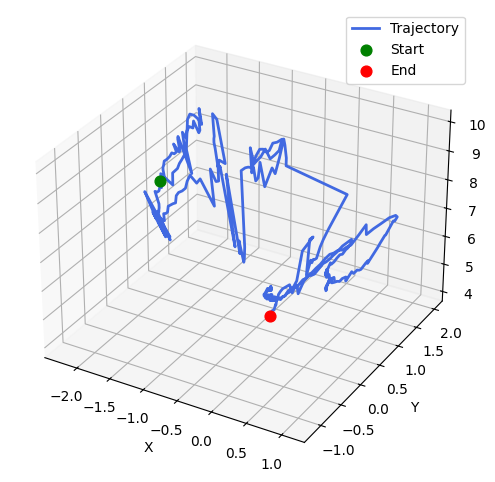

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

traj = np.array(ball_location)
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(projection='3d')

# Unpack columns directly into plot and scatter
ax.plot(*traj.T, color='royalblue', linewidth=2, label='Trajectory')
ax.scatter(*traj[0], color='green', s=60, label='Start')
ax.scatter(*traj[-1], color='red', s=60, label='End')

ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')
ax.legend()
plt.show()

In [ ]:
import cv2
from ultralytics import YOLO

BOX_COLOR = (0, 255, 0)  # BGR (green)


def main(video_path, model_path="best.pt", output_path="detections.mp4", conf=0.25):
  model = YOLO(model_path)

  video = cv2.VideoCapture(video_path)
  if not video.isOpened():
    raise FileNotFoundError(f"Couldn't open video: {video_path}")

  fps = video.get(cv2.CAP_PROP_FPS) or 30
  width = int(video.get(cv2.CAP_PROP_FRAME_WIDTH))
  height = int(video.get(cv2.CAP_PROP_FRAME_HEIGHT))
  writer = cv2.VideoWriter(output_path, cv2.VideoWriter_fourcc(*"mp4v"), fps, (width, height))

  while True:
    success, frame = video.read()
    if not success:
      break

    # Run the model on this frame
    result = model.predict(source=frame, conf=conf, verbose=False)[0]

    # Draw every detected box with its class name and confidence
    for box in result.boxes:
      x1, y1, x2, y2 = (int(v) for v in box.xyxy[0].tolist())
      label = f"{model.names[int(box.cls)]} {float(box.conf):.2f}"
      cv2.rectangle(frame, (x1, y1), (x2, y2), BOX_COLOR, 2)
      cv2.putText(frame, label, (x1, max(15, y1 - 5)), cv2.FONT_HERSHEY_SIMPLEX, 0.6, BOX_COLOR, 2)

    writer.write(frame)

  video.release()
  writer.release()
  print(f"Saved to {output_path}")


if __name__ == "__main__":
  main(input("Enter video name: "))

Enter video name: bigballz.mp4
Saved to detections.mp4
